# Simple aerodynamic analysis

This notebook contains a simple set of aerodynamic analysis done on some airfoils done using neuralfoil (via the aerosandbox wrapper. Some further analysis tools (Principal Orthogonal Decomposition, FPCA) are tested later on. The goal is simply to illustrate what kind of field analysis can be done using Aerosandbox. 

Operating conditions used: 
- Angle of attack $\alpha$ 0 when nominal, -5, 5 for sweeps
- Reynolds 2e6 when nominal, 2e6 += 1e5 for sweeps

Model used: Neuralfoil (via aerosandbox) with `model_size` parameter set at `xxx_large` 

In [2]:
import aerosandbox as asb
import numpy as np 
from matplotlib import pyplot as plt 


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/rraanto/.local/lib/python3.13/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/rraanto/.local/lib/python3.13/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/home/rraanto/.local/lib/python3.13/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/home/rraanto/.lo

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/rraanto/.local/lib/python3.13/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/rraanto/.local/lib/python3.13/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/home/rraanto/.local/lib/python3.13/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/home/rraanto/.lo

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/rraanto/.local/lib/python3.13/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/rraanto/.local/lib/python3.13/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/home/rraanto/.local/lib/python3.13/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/home/rraanto/.lo

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.1 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [3]:
# generate airfoil 
airfoil = asb.Airfoil("NACA0006")
# airfoil.draw(backend="matplotlib")

# generate aerodynamimc fields 
_grid_res = 100
alpha = 0
reynold = 2e6
alphas = np.linspace(-5, 5, _grid_res)
reynolds = np.linspace(reynold - 1e5, reynold + 1e5, _grid_res)

## for field 
a_batch, re_batch = np.meshgrid(alphas, reynolds)

## different sweeps 
alpha_sweep = airfoil.get_aero_from_neuralfoil(alpha=alphas, Re=reynold, model_size="xxxlarge")
re_sweep = airfoil.get_aero_from_neuralfoil(alpha=alpha, Re=reynold, model_size='xxxlarge')

## aerodynamic field 
aero_fields = airfoil.get_aero_from_neuralfoil(alpha=a_batch.flatten(), Re=re_batch.flatten(), model_size="xxxlarge")

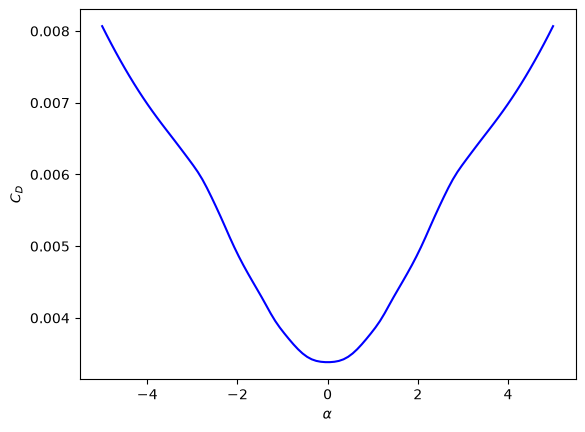

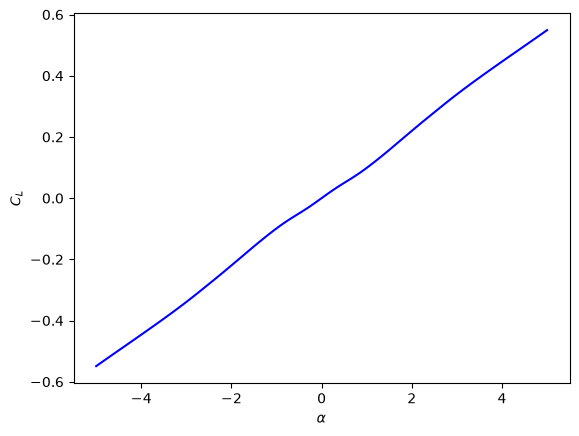

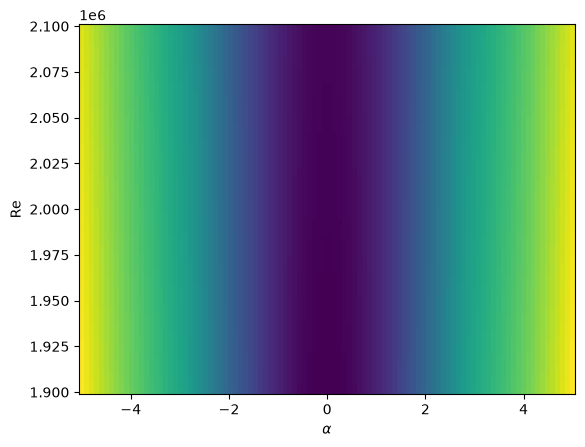

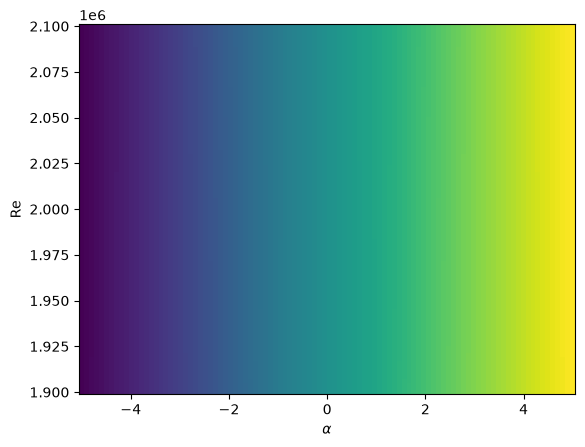

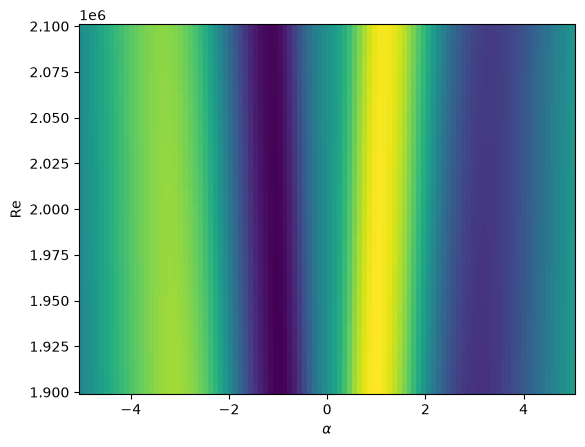

In [4]:
## alpha and Re sweep plots 
## CD 
plt.plot(alphas, alpha_sweep["CD"], linestyle='-', color='blue') 
plt.xlabel("$\\alpha$")
plt.ylabel("$C_D$")
plt.show()

## CL 
plt.plot(alphas, alpha_sweep["CL"], linestyle='-', color='blue') 
plt.xlabel("$\\alpha$")
plt.ylabel("$C_L$")
plt.show() 

## Field plots
plt.pcolormesh(a_batch, re_batch, aero_fields["CD"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.show()

plt.pcolormesh(a_batch, re_batch, aero_fields["CL"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.show()

plt.pcolormesh(a_batch, re_batch, aero_fields["CM"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.show()

# POD of the aerodynamic fields 

Proper Orthogonal decomposition is one of the first field reduction methods that are used in this project. The next section displays a simple manner of how to apply the technique to an aerodynamic field using Python. 

## on POD 
POD is also known as KL (Karhunen Loeve) decomposition, consists of decomposing a random field in some well-chosen variance maximising orthogonal basis.   